# Land Use Classification from Satellite Images Using Deep Learning
**COMP-671 Deep Learning — Final Project** · Yagna Saikumar

**Problem.** Governments and environmental groups need to know how land is used (shrinking forests, growing cities, farmland). Manual checking across large areas is slow and expensive. This notebook trains a model that takes a small satellite image and predicts its land-use class.

**Data.** EuroSAT (RGB): ~27,000 labelled 64×64 Sentinel-2 images, 10 classes.

**Plan.**
1. Load data and make a fixed, saved train/val/test split (70/15/15, stratified)
2. Exploratory data analysis
3. **Baseline:** logistic regression on downsampled pixels
4. **CNN** trained from scratch
5. **Controlled comparison:** CNN *with* vs *without* data augmentation (everything else identical)
6. Evaluation: accuracy, macro F1, confusion matrix, failure analysis
7. Inference demo on unseen images

**Success criteria.** Primary metric: test macro-F1. A meaningful result is a CNN that beats the pixel baseline by ≥ 15 points and reaches ≥ 90 % test accuracy. Augmentation counts as helping if it raises macro-F1 by more than ~0.5 points.

## 1. Setup & configuration

In [1]:
import os, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from tqdm.auto import tqdm

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
DATA_DIR, RESULTS_DIR, MODELS_DIR = 'data', 'results', 'models'
for d in (DATA_DIR, RESULTS_DIR, MODELS_DIR): os.makedirs(d, exist_ok=True)
print('Device:', DEVICE)

Device: cuda


In [2]:
# All key hyperparameters in one place (copied into the README)
CONFIG = dict(seed=SEED, split='70/15/15 stratified', batch_size=128, epochs=25, lr=1e-3,
              weight_decay=1e-4, optimizer='Adam', scheduler='CosineAnnealing', dropout=0.3,
              baseline='LogReg on 16x16 RGB pixels', augmentation='hflip+vflip+rot90')
json.dump(CONFIG, open(f'{RESULTS_DIR}/config.json', 'w'), indent=2); CONFIG

{'seed': 42,
 'split': '70/15/15 stratified',
 'batch_size': 128,
 'epochs': 25,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'optimizer': 'Adam',
 'scheduler': 'CosineAnnealing',
 'dropout': 0.3,
 'baseline': 'LogReg on 16x16 RGB pixels',
 'augmentation': 'hflip+vflip+rot90'}

## 2. Load EuroSAT and create a reproducible split
The split indices are saved to `results/splits.json` so anyone can repeat the experiments exactly.

In [3]:
full = datasets.EuroSAT(root=DATA_DIR, download=True)   # ~90 MB
CLASSES = full.classes
labels = np.array(full.targets)
print(len(full), 'images |', len(CLASSES), 'classes:', CLASSES)

split_path = os.path.join(RESULTS_DIR, 'splits.json')
if os.path.exists(split_path):
    splits = json.load(open(split_path))
else:
    idx = np.arange(len(full))
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SEED)
    splits = {'train': tr.tolist(), 'val': va.tolist(), 'test': te.tolist()}
    json.dump(splits, open(split_path, 'w'))
print({k: len(v) for k, v in splits.items()})

100%|██████████| 94.3M/94.3M [00:01<00:00, 77.2MB/s]


27000 images | 10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
{'train': 18900, 'val': 4050, 'test': 4050}


## 3. Exploratory data analysis
EuroSAT is roughly balanced (2,000–3,000 images per class), which is why **macro-F1** (every class weighted equally) is reported next to accuracy.

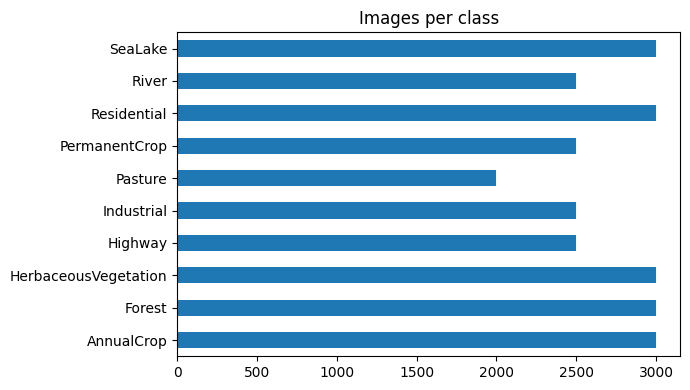

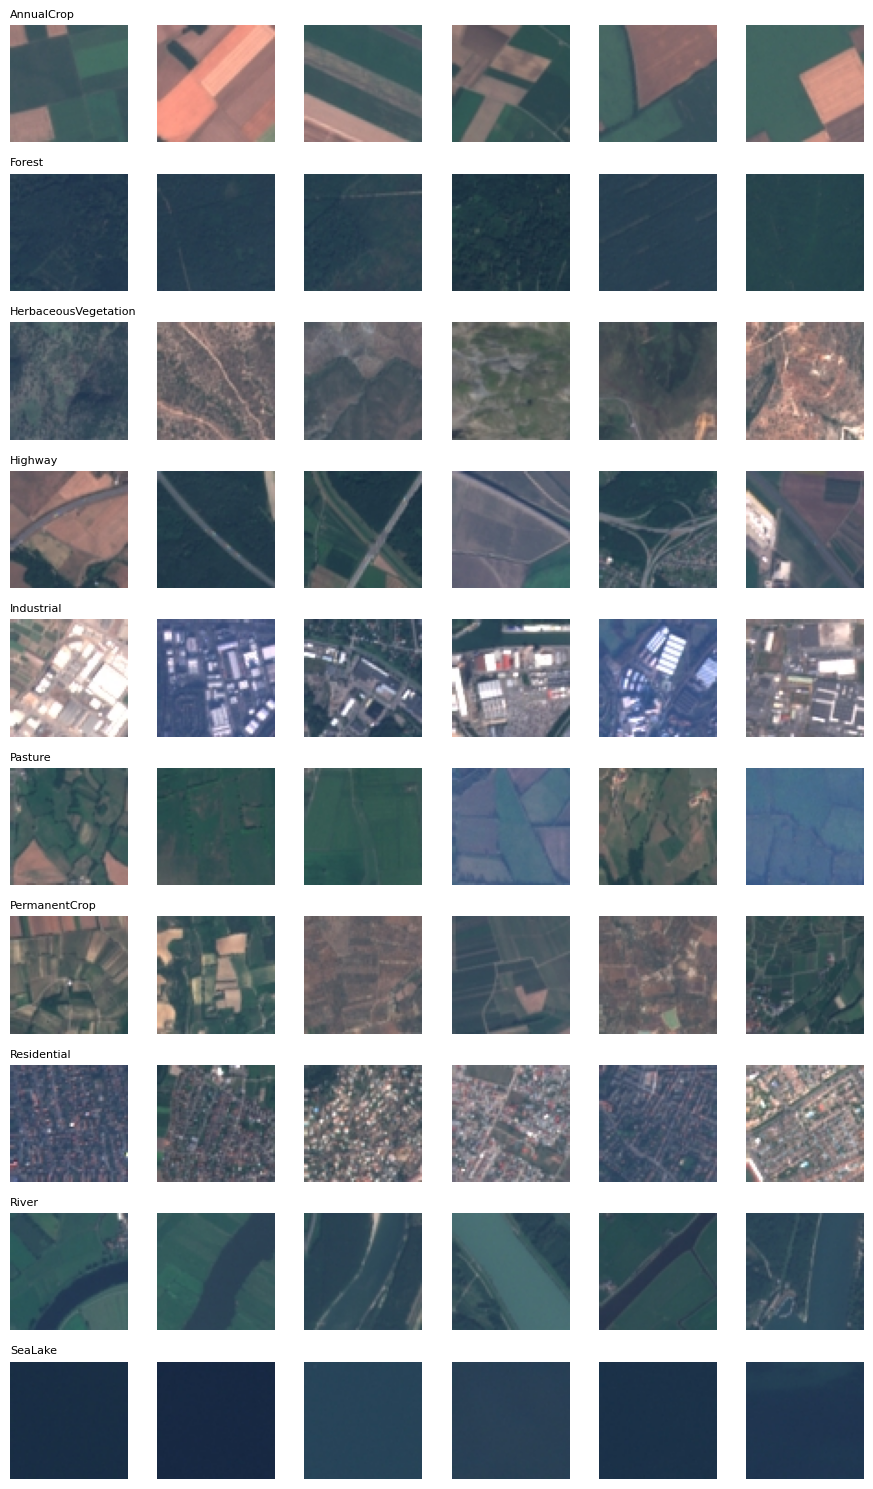

In [4]:
counts = pd.Series(labels).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES)
counts.plot.barh(figsize=(7,4), title='Images per class'); plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/class_distribution.png'); plt.show()

fig, axes = plt.subplots(len(CLASSES), 6, figsize=(9, 15))
for c in range(len(CLASSES)):
    ids = np.random.choice(np.where(labels == c)[0], 6, replace=False)
    for j, i in enumerate(ids):
        axes[c, j].imshow(full[i][0]); axes[c, j].axis('off')
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc='left')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/samples.png'); plt.show()

In [5]:
# Per-channel mean/std from the TRAINING split only (no test leakage)
to_t = transforms.ToTensor()
X = torch.stack([to_t(full[i][0]) for i in splits['train'][:5000]])
MEAN, STD = X.mean((0,2,3)).tolist(), X.std((0,2,3)).tolist()
print('mean', np.round(MEAN,3), 'std', np.round(STD,3))

mean [0.346 0.382 0.409] std [0.203 0.137 0.116]


## 4. Data pipelines
Two training transforms: **plain** (normalize only) and **augmented** (flips + 90° rotations — valid for overhead imagery, since there is no 'up' in a satellite view). Val/test are never augmented.

In [6]:
class Wrap(Dataset):
    def __init__(self, base, ids, tf): self.base, self.ids, self.tf = base, ids, tf
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        img, y = self.base[self.ids[i]]; return self.tf(img), y

norm = transforms.Normalize(MEAN, STD)
TF_PLAIN = transforms.Compose([transforms.ToTensor(), norm])
class Rot90:
    def __call__(self, x): return torch.rot90(x, random.randint(0,3), (1,2))
TF_AUG = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                             transforms.ToTensor(), Rot90(), norm])

BATCH = CONFIG['batch_size']
def loaders(train_tf):
    g = torch.Generator().manual_seed(SEED)
    return (DataLoader(Wrap(full, splits['train'], train_tf), BATCH, shuffle=True, num_workers=0, generator=g),
            DataLoader(Wrap(full, splits['val'],  TF_PLAIN), BATCH, num_workers=0),
            DataLoader(Wrap(full, splits['test'], TF_PLAIN), BATCH, num_workers=0))

## 5. Baseline: logistic regression on pixels
Images downsampled to 16×16×3 = 768 features. If the CNN cannot clearly beat this, deep learning is not justified.

In [7]:
def pixel_features(ids, size=16):
    tf = transforms.Compose([transforms.Resize(size), transforms.ToTensor()])
    return np.stack([tf(full[i][0]).flatten().numpy() for i in tqdm(ids)]), labels[ids]

Xtr, ytr = pixel_features(splits['train']); Xte, yte = pixel_features(splits['test'])
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
t0 = time.time()
base = LogisticRegression(max_iter=2000, C=1.0).fit((Xtr-mu)/sd, ytr)
pred_base = base.predict((Xte-mu)/sd)
RESULTS = {'Baseline (LogReg)': {'acc': accuracy_score(yte, pred_base),
                                 'f1': f1_score(yte, pred_base, average='macro')}}
print(RESULTS, f'{time.time()-t0:.0f}s')

  0%|          | 0/18900 [00:00<?, ?it/s]

  0%|          | 0/4050 [00:00<?, ?it/s]

{'Baseline (LogReg)': {'acc': 0.44666666666666666, 'f1': 0.4386814751683872}} 174s


## 6. CNN architecture
Four conv blocks (Conv→BatchNorm→ReLU ×2, then max-pool), global average pooling, dropout, linear head. Loss: cross-entropy (classes are roughly balanced, so no weighting). Optimizer: Adam with cosine learning-rate decay. Model selection: best validation macro-F1.

In [8]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))
class LandCNN(nn.Module):
    def __init__(self, n=10):
        super().__init__()
        self.features = nn.Sequential(block(3,32), block(32,64), block(64,128), block(128,256))  # 64→4
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))
print(f'{sum(p.numel() for p in LandCNN().parameters()):,} parameters')

1,176,746 parameters


## 7. Training and evaluation helpers

In [9]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y = [], []
    for x, y in dl:
        P.append(model(x.to(DEVICE)).argmax(1).cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

def train(name, train_tf, epochs=CONFIG['epochs'], lr=CONFIG['lr']):
    set_seed()                                   # identical init for fair comparison
    tr_dl, va_dl, te_dl = loaders(train_tf)
    model = LandCNN(len(CLASSES)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist, best = [], -1
    for ep in range(epochs):
        model.train(); tot, n = 0, 0
        for x, y in tqdm(tr_dl, leave=False, desc=f'{name} ep{ep+1}'):
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()*len(y); n += len(y)
        sched.step()
        yv, pv = predict(model, va_dl)
        f1 = f1_score(yv, pv, average='macro')
        hist.append({'epoch': ep+1, 'train_loss': tot/n, 'val_acc': accuracy_score(yv, pv), 'val_f1': f1})
        print(f"ep{ep+1:02d} loss {tot/n:.4f} | val acc {hist[-1]['val_acc']:.4f} f1 {f1:.4f}")
        if f1 > best:
            best = f1; torch.save(model.state_dict(), f'{MODELS_DIR}/{name}.pth')
    model.load_state_dict(torch.load(f'{MODELS_DIR}/{name}.pth'))
    yt, pt = predict(model, te_dl)
    RESULTS[name] = {'acc': accuracy_score(yt, pt), 'f1': f1_score(yt, pt, average='macro')}
    pd.DataFrame(hist).to_csv(f'{RESULTS_DIR}/{name}_history.csv', index=False)
    return model, pd.DataFrame(hist), yt, pt

## 8. Train CNN — no augmentation

In [10]:
cnn_plain, h_plain, yt, pt_plain = train('CNN_plain', TF_PLAIN)

CNN_plain ep1:   0%|          | 0/148 [00:00<?, ?it/s]

ep01 loss 0.8282 | val acc 0.7491 f1 0.7444


CNN_plain ep2:   0%|          | 0/148 [00:00<?, ?it/s]

ep02 loss 0.5101 | val acc 0.8163 f1 0.8036


CNN_plain ep3:   0%|          | 0/148 [00:00<?, ?it/s]

...

ep23 loss 0.0288 | val acc 0.9684 f1 0.9672


CNN_plain ep24:   0%|          | 0/148 [00:00<?, ?it/s]

ep24 loss 0.0262 | val acc 0.9691 f1 0.9680


CNN_plain ep25:   0%|          | 0/148 [00:00<?, ?it/s]

ep25 loss 0.0248 | val acc 0.9701 f1 0.9690


## 9. Controlled comparison — CNN with augmentation
Only the training transform changes. Architecture, seed, split, optimizer, epochs and learning rate are identical.

In [11]:
cnn_aug, h_aug, yt, pt_aug = train('CNN_aug', TF_AUG)

CNN_aug ep1:   0%|          | 0/148 [00:00<?, ?it/s]

ep01 loss 0.8415 | val acc 0.7743 f1 0.7630


CNN_aug ep2:   0%|          | 0/148 [00:00<?, ?it/s]

ep02 loss 0.5177 | val acc 0.8143 f1 0.8062


CNN_aug ep3:   0%|          | 0/148 [00:00<?, ?it/s]

...

ep23 loss 0.0653 | val acc 0.9684 f1 0.9675


CNN_aug ep24:   0%|          | 0/148 [00:00<?, ?it/s]

ep24 loss 0.0614 | val acc 0.9701 f1 0.9692


CNN_aug ep25:   0%|          | 0/148 [00:00<?, ?it/s]

ep25 loss 0.0609 | val acc 0.9699 f1 0.9690


## 10. Results

,Test accuracy,Test macro-F1
Baseline (LogReg),0.4467,0.4387
CNN_plain,0.9746,0.9738
CNN_aug,0.9788,0.9782


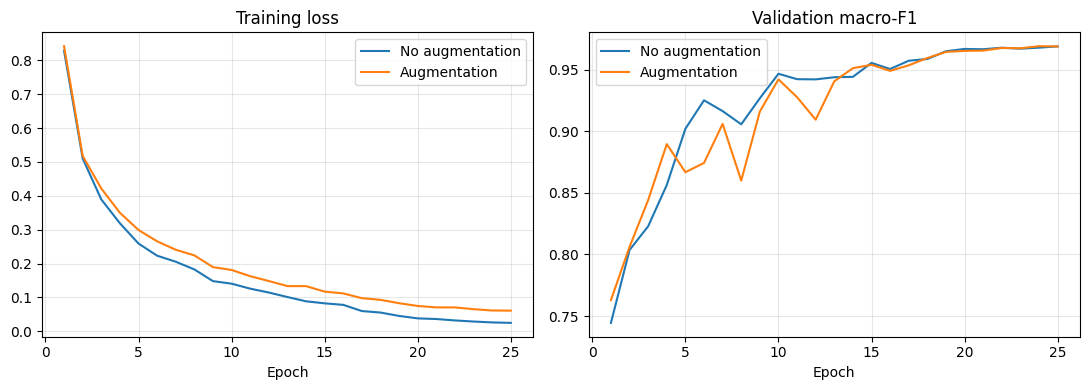

In [12]:
res = pd.DataFrame(RESULTS).T.rename(columns={'acc':'Test accuracy','f1':'Test macro-F1'}).round(4)
res.to_csv(f'{RESULTS_DIR}/results_summary.csv'); display(res)

fig, ax = plt.subplots(1, 2, figsize=(11,4))
for h, lbl in [(h_plain,'No augmentation'), (h_aug,'Augmentation')]:
    ax[0].plot(h.epoch, h.train_loss, label=lbl); ax[1].plot(h.epoch, h.val_f1, label=lbl)
ax[0].set(title='Training loss', xlabel='Epoch'); ax[1].set(title='Validation macro-F1', xlabel='Epoch')
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/learning_curves.png'); plt.show()

Best model: CNN_aug 

                      precision    recall  f1-score   support

          AnnualCrop      0.943     0.958     0.950       450
              Forest      0.987     1.000     0.993       450
HerbaceousVegetation      0.982     0.980     0.981       450
             Highway      0.979     0.981     0.980       375
          Industrial      0.981     0.989     0.985       375
             Pasture      0.980     0.960     0.970       300
       PermanentCrop      0.957     0.957     0.957       375
         Residential      1.000     0.991     0.996       450
               River      0.976     0.971     0.973       375
             SeaLake      1.000     0.991     0.996       450

            accuracy                          0.979      4050
           macro avg      0.979     0.978     0.978      4050
        weighted avg      0.979     0.979     0.979      4050



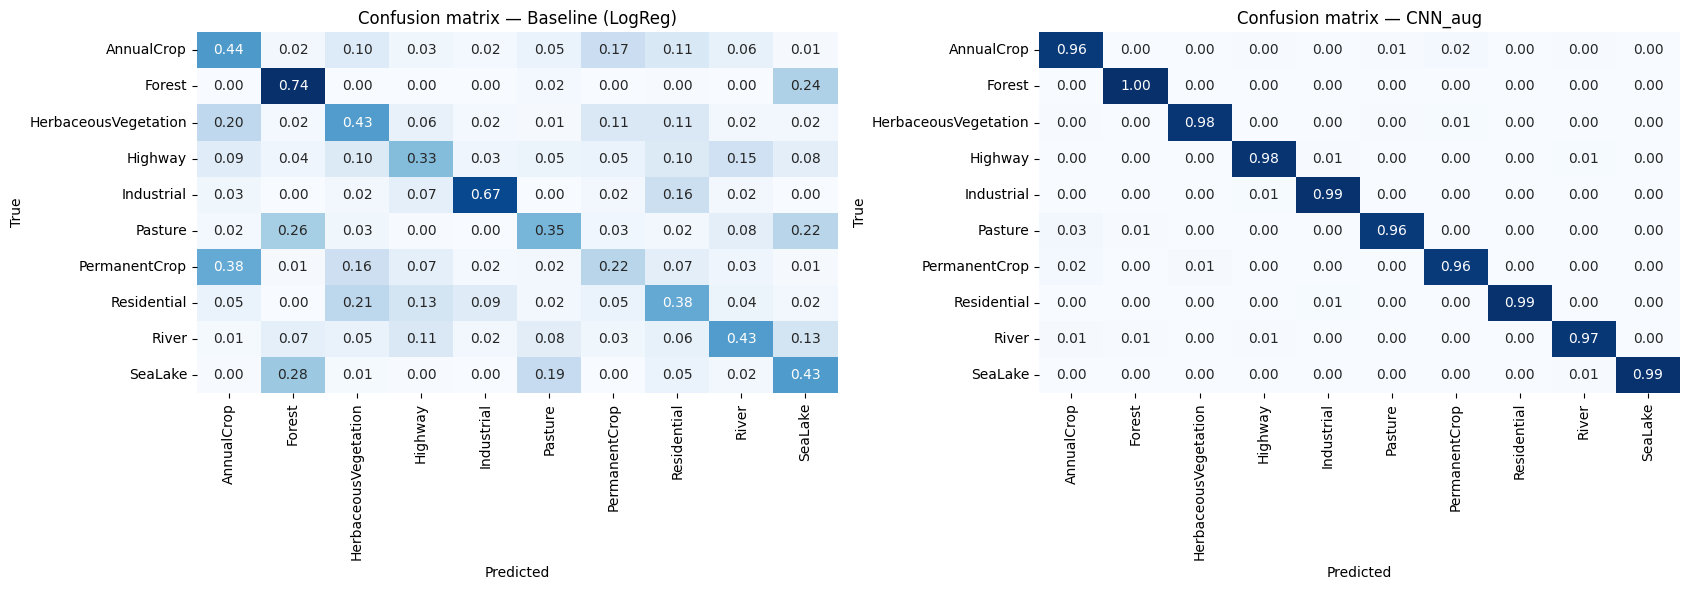

In [13]:
best_name = max(['CNN_plain','CNN_aug'], key=lambda k: RESULTS[k]['f1'])
best_pred = pt_aug if best_name == 'CNN_aug' else pt_plain
print('Best model:', best_name, '\n')
print(classification_report(yt, best_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(17,6))
for a, p, t in [(ax[0], pred_base, 'Baseline (LogReg)'), (ax[1], best_pred, best_name)]:
    cm = confusion_matrix(yt, p, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set(title=f'Confusion matrix — {t}', xlabel='Predicted', ylabel='True')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/confusion_matrices.png'); plt.show()

## 11. Failure analysis — what does the model get wrong?

Most common confusions (true -> predicted):
  AnnualCrop             -> PermanentCrop          10
  Pasture                -> AnnualCrop             9
  PermanentCrop          -> AnnualCrop             8
  River                  -> AnnualCrop             5
  PermanentCrop          -> HerbaceousVegetation   5


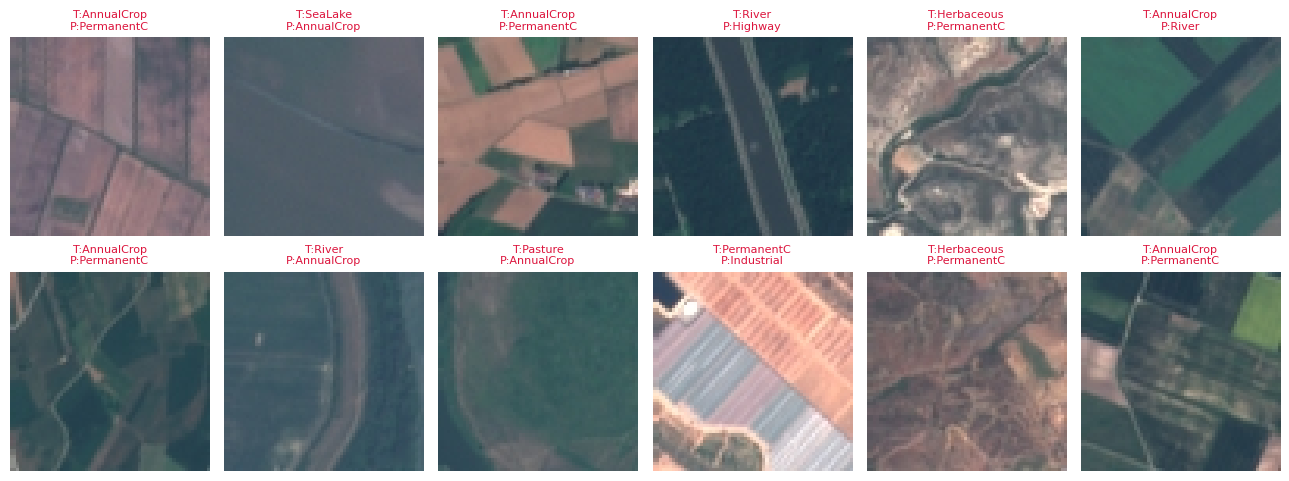

In [14]:
test_ids = np.array(splits['test']); wrong = np.where(best_pred != yt)[0]
cm = confusion_matrix(yt, best_pred); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:5], cm.shape))[0]
print('Most common confusions (true -> predicted):')
for t, p in top: print(f'  {CLASSES[t]:22s} -> {CLASSES[p]:22s} {cm[t,p]}')

sel = np.random.choice(wrong, min(12, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13,5))
for a, i in zip(axes.ravel(), sel):
    a.imshow(full[test_ids[i]][0]); a.axis('off')
    a.set_title(f'T:{CLASSES[yt[i]][:10]}\nP:{CLASSES[best_pred[i]][:10]}', fontsize=8, color='crimson')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/misclassified.png'); plt.show()

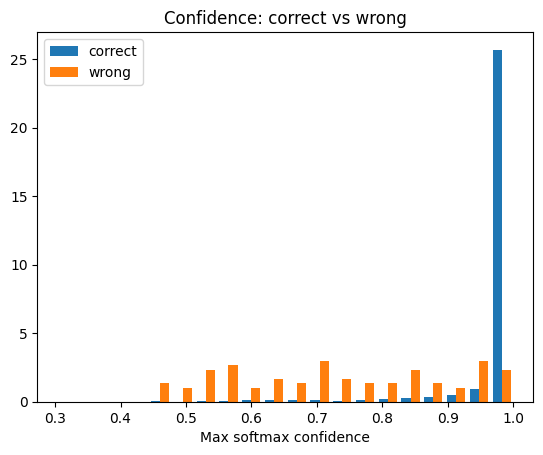

Per-class F1 (worst first):
AnnualCrop              0.950
PermanentCrop           0.957
Pasture                 0.970
River                   0.973
Highway                 0.980
HerbaceousVegetation    0.981
Industrial              0.985
Forest                  0.993
Residential             0.996
SeaLake                 0.996
dtype: float64


In [15]:
# Where is the model uncertain? Confidence of correct vs wrong predictions
best_model = cnn_aug if best_name == 'CNN_aug' else cnn_plain
_, _, te_dl = loaders(TF_PLAIN); best_model.eval(); conf = []
with torch.no_grad():
    for x, _ in te_dl: conf.append(F.softmax(best_model(x.to(DEVICE)), 1).max(1).values.cpu())
conf = torch.cat(conf).numpy(); ok = best_pred == yt
plt.hist([conf[ok], conf[~ok]], bins=20, label=['correct','wrong'], density=True)
plt.legend(); plt.xlabel('Max softmax confidence'); plt.title('Confidence: correct vs wrong')
plt.savefig(f'{RESULTS_DIR}/confidence.png'); plt.show()
per_class = pd.Series(f1_score(yt, best_pred, average=None), index=CLASSES).sort_values()
print('Per-class F1 (worst first):'); print(per_class.round(3))

## 12. Inference demo
Load the saved weights from disk (as a user would) and classify test images the model never trained on.

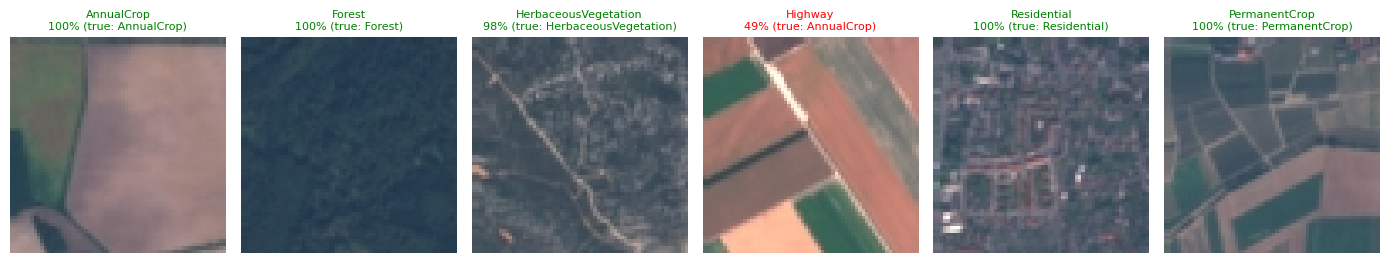

In [16]:
def classify(img, model_path=f'{MODELS_DIR}/{best_name}.pth'):
    m = LandCNN(len(CLASSES)).to(DEVICE); m.load_state_dict(torch.load(model_path, map_location=DEVICE)); m.eval()
    with torch.no_grad():
        p = F.softmax(m(TF_PLAIN(img).unsqueeze(0).to(DEVICE)), 1)[0].cpu()
    k = p.argmax().item(); return CLASSES[k], p[k].item()

fig, axes = plt.subplots(1, 6, figsize=(14,3))
for a, i in zip(axes, np.random.choice(splits['test'], 6, replace=False)):
    img, y = full[i]; lab, c = classify(img)
    a.imshow(img); a.axis('off')
    a.set_title(f'{lab}\n{c:.0%} (true: {CLASSES[y]})', fontsize=8, color='green' if lab == CLASSES[y] else 'red')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/inference_demo.png'); plt.show()

## 13. Conclusions

* **CNN vs baseline:** The CNN reaches 97.9 % test accuracy vs 44.7 % for logistic regression, a gain of 53 points. This shows spatial feature learning is needed; raw pixel colour alone is not enough.
* **Controlled comparison (augmentation):** Augmentation changed macro-F1 from 0.974 to 0.978. The learning curves show both models reach the same validation F1 (~0.969), but final training loss is 0.025 without augmentation vs 0.061 with it, so augmentation reduces overfitting while barely changing test accuracy.
* **Errors:** The most confused classes were AnnualCrop and PermanentCrop (plus Pasture → AnnualCrop), which look similar from above as green fields with row texture.
* **Limitations:** Only RGB bands (Sentinel-2 has 13), 10 classes, a single training seed, and all images come from Europe, so performance on other regions is not tested.
* **Ethics:** Land-use maps influence zoning and funding decisions; errors on crop classes could misdirect agricultural resources. Sentinel-2 at 10 m/pixel cannot identify individuals, so privacy risk is low.
* **Future work:** Use all 13 spectral bands, try transfer learning (e.g. ResNet-18), run multiple seeds, and test on a held-out geographic region.